In [1]:
import os
import pickle
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score, roc_curve, auc
)
from sklearn.preprocessing import label_binarize
import seaborn as sns
import matplotlib.pyplot as plt

# === Settings ===
train_dir = 'plntdata/Final_DataSet/train'
val_dir = 'plntdata/Final_DataSet/valid'
IMG_SIZE = (224, 224)
BATCH_SIZE = 96
EPOCHS = 26

# === Early stopping ===
early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# === Plot training curves ===
def plot_accuracy_loss(history, model_name):
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(history['accuracy'], label='Train Accuracy')
    plt.plot(history['val_accuracy'], label='Val Accuracy')
    plt.title(f"{model_name} Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history['loss'], label='Train Loss')
    plt.plot(history['val_loss'], label='Val Loss')
    plt.title(f"{model_name} Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.savefig(f"{model_name}_accuracy_loss.png")
    plt.show()

# === Plot multi-class ROC curve ===
def plot_multiclass_roc(y_true, y_probs, class_names, model_name):
    y_true_bin = label_binarize(y_true, classes=range(len(class_names)))
    fpr, tpr, roc_auc = {}, {}, {}

    for i in range(len(class_names)):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_probs[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    plt.figure(figsize=(10, 8))
    for i in range(len(class_names)):
        plt.plot(fpr[i], tpr[i], label=f'{class_names[i]} (AUC = {roc_auc[i]:.2f})')

    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'{model_name} - ROC Curve')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.savefig(f"{model_name}_roc_curve.png")
    plt.show()

# === Train VGG16 Model ===
def train_vgg16():
    model_name = "VGG16"
    print(f"\n🚀 Training {model_name}")

    # === Data Generators ===
    train_gen = ImageDataGenerator(preprocessing_function=vgg_preprocess).flow_from_directory(
        train_dir, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical', shuffle=True
    )
    val_gen = ImageDataGenerator(preprocessing_function=vgg_preprocess).flow_from_directory(
        val_dir, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False
    )

    # === Base Model ===
    base_model = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    base_model.trainable = False

    # === Full Model ===
    model = models.Sequential([
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(train_gen.num_classes, activation='softmax')
    ])

    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

    # === Training ===
    history = model.fit(
        train_gen,
        validation_data=val_gen,
        epochs=EPOCHS,
        callbacks=[early_stop],
        verbose=2
    )

    # === Save history with pickle ===
    with open(f"{model_name}_history.pkl", "wb") as f:
        pickle.dump(history.history, f)
    print(f"✅ Training history saved as {model_name}_history.pkl")

    # === Save model ===
    model.save(f"{model_name}_full_model.h5")
    print(f"✅ Saved model as {model_name}_full_model.h5")

    # === Evaluation ===
    val_gen.reset()
    preds = model.predict(val_gen)
    y_pred = np.argmax(preds, axis=1)
    y_true = val_gen.classes
    labels = list(val_gen.class_indices.keys())

    print("\n📊 Classification Report:")
    print(classification_report(y_true, y_pred, target_names=labels))

    # === Metrics ===
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)

    print(f"\n✅ Accuracy : {acc:.4f}")
    print(f"✅ Precision: {prec:.4f}")
    print(f"✅ Recall   : {rec:.4f}")
    print(f"✅ F1 Score : {f1:.4f}")

    # === Confusion Matrix ===
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt="d", xticklabels=labels, yticklabels=labels, cmap="Blues")
    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.savefig(f"{model_name}_confusion_matrix.png")
    plt.show()

    # === Plots ===
    plot_accuracy_loss(history.history, model_name)
    plot_multiclass_roc(y_true, preds, labels, model_name)

    # === Cleanup ===
    tf.keras.backend.clear_session()



🚀 Training VGG16
Found 70295 images belonging to 38 classes.
Found 17572 images belonging to 38 classes.
Epoch 1/26
733/733 - 243s - loss: 1.3801 - accuracy: 0.6169 - val_loss: 0.3152 - val_accuracy: 0.9066 - 243s/epoch - 331ms/step
Epoch 2/26
733/733 - 192s - loss: 0.5291 - accuracy: 0.8327 - val_loss: 0.2139 - val_accuracy: 0.9316 - 192s/epoch - 262ms/step
Epoch 3/26
733/733 - 198s - loss: 0.4090 - accuracy: 0.8679 - val_loss: 0.1694 - val_accuracy: 0.9461 - 198s/epoch - 270ms/step
Epoch 4/26
733/733 - 202s - loss: 0.3395 - accuracy: 0.8896 - val_loss: 0.1485 - val_accuracy: 0.9528 - 202s/epoch - 275ms/step
Epoch 5/26
733/733 - 183s - loss: 0.3070 - accuracy: 0.8993 - val_loss: 0.1381 - val_accuracy: 0.9536 - 183s/epoch - 249ms/step
Epoch 6/26
733/733 - 201s - loss: 0.2876 - accuracy: 0.9048 - val_loss: 0.1317 - val_accuracy: 0.9575 - 201s/epoch - 274ms/step
Epoch 7/26
733/733 - 204s - loss: 0.2684 - accuracy: 0.9108 - val_loss: 0.1264 - val_accuracy: 0.9569 - 204s/epoch - 278ms/ste

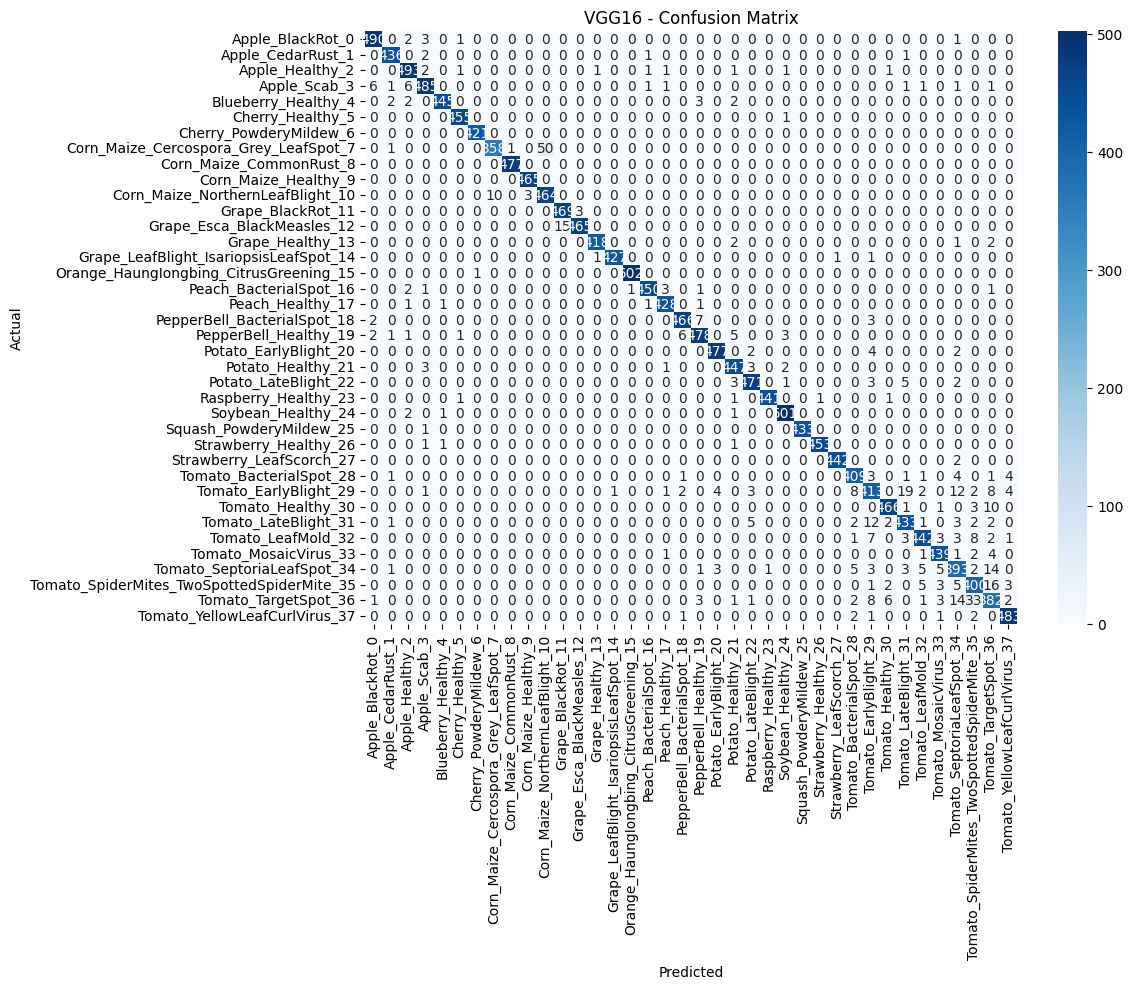

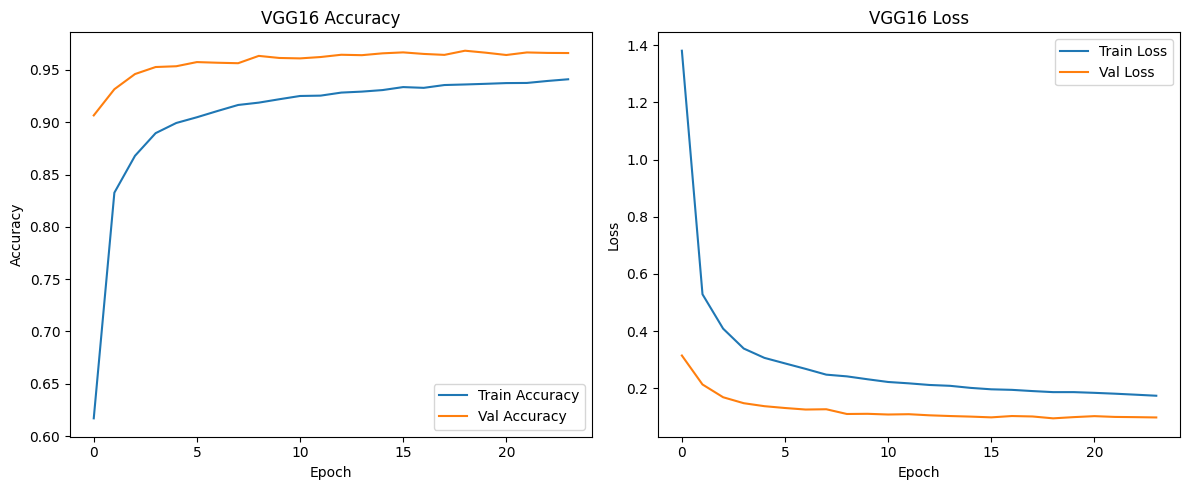

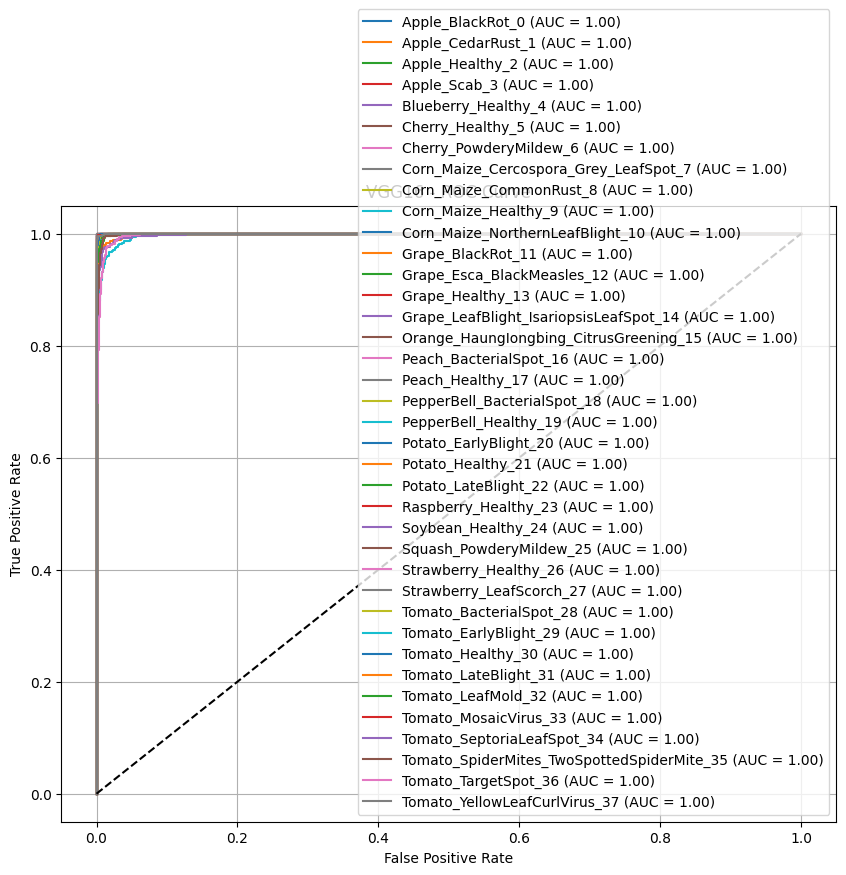

In [2]:
train_vgg16()